In [1]:
'''Implement user-upload functionality within the app to allow admission officers to analyze custom applicant datasets and generate prediction reports dynamically.'''

'Implement user-upload functionality within the app to allow admission officers to analyze custom applicant datasets and generate prediction reports dynamically.'

In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import io
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error


In [2]:
# load dataset and prepare features
df = pd.read_csv('Adm.csv')
df.columns = df.columns.str.strip()
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target = 'Chance of Admit'

print('dataset loaded with shape:', df.shape)
df.head()


dataset loaded with shape: (1000, 12)
Out[1]: 
   Serial No.  GRE Score  ...                             University_Name  region
0           1        337  ...    Indian Institute of Technology Kharagpur    East
1           2        324  ...  National Institute of Technology Karnataka   South
2           3        316  ...                          Gujarat University    West
3           4        322  ...                        Jamia Millia Islamia   North
4           5        314  ...                        Jamia Millia Islamia   North

[5 rows x 12 columns]


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.96,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.80,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.67,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.78,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.63,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [3]:
# train and evaluate admission prediction model
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

joblib.dump(model, 'admission_model.pkl')
y_pred_test = model.predict(X_test)
print('test r2 score:', round(r2_score(y_test, y_pred_test), 4))
print('test mae:', round(mean_absolute_error(y_test, y_pred_test), 4))


test r2 score: 0.9084
test mae: 0.0234


In [4]:
# function to generate comprehensive batch prediction report
def generate_dynamic_prediction_report(file_source, model_path='admission_model.pkl', high_cutoff=0.80, med_cutoff=0.60):
    data = pd.read_csv(file_source) if isinstance(file_source, str) else pd.read_csv(io.BytesIO(file_source))
    data.columns = data.columns.str.strip()
    feat_cols = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
    
    trained_model = joblib.load(model_path)
    data['Predicted_Chance'] = trained_model.predict(data[feat_cols]).clip(0, 1)
    data['Percentile_Rank'] = (data['Predicted_Chance'].rank(pct=True) * 100).round(1)
    
    data['Admission_Tier'] = np.where(data['Predicted_Chance'] >= high_cutoff, 'Tier 1 - Strong Admit',
                             np.where(data['Predicted_Chance'] >= med_cutoff, 'Tier 2 - Competitive Review', 'Tier 3 - Low Probability'))
    
    t1_mask = data['Admission_Tier'] == 'Tier 1 - Strong Admit'
    t2_mask = data['Admission_Tier'] == 'Tier 2 - Competitive Review'
    t3_mask = data['Admission_Tier'] == 'Tier 3 - Low Probability'
    
    summary = {
        'total_applicants': len(data),
        'tier_1_strong_count': int(t1_mask.sum()),
        'tier_2_competitive_count': int(t2_mask.sum()),
        'tier_3_low_count': int(t3_mask.sum()),
        'average_predicted_chance': round(data['Predicted_Chance'].mean(), 4),
        'tier_1_avg_cgpa': round(data[t1_mask]['CGPA'].mean(), 2) if t1_mask.sum() > 0 else 0,
        'tier_1_avg_gre': round(data[t1_mask]['GRE Score'].mean(), 1) if t1_mask.sum() > 0 else 0,
        'research_admit_rate': round(data[data['Research'] == 1]['Predicted_Chance'].mean(), 4)
    }
    
    return data, summary


In [5]:
# generate dynamic prediction report for applicant cohort
report_df, summary_metrics = generate_dynamic_prediction_report('Adm.csv')
print('dynamic prediction report generated for', len(report_df), 'applicants')


dynamic prediction report generated for 1000 applicants


In [6]:
# display executive summary metrics of applicant batch
summary_table = pd.DataFrame(list(summary_metrics.items()), columns=['metric', 'value'])
summary_table


Out[1]: 
                     metric      value
0          total_applicants  1000.0000
1       tier_1_strong_count   214.0000
2  tier_2_competitive_count   657.0000
3          tier_3_low_count   129.0000
4  average_predicted_chance     0.7172
5           tier_1_avg_cgpa     9.3500
6            tier_1_avg_gre   325.3000
7       research_admit_rate     0.7572


,metric,value
0,total_applicants,1000.0000
1,tier_1_strong_count,214.0000
2,tier_2_competitive_count,657.0000
3,tier_3_low_count,129.0000
4,average_predicted_chance,0.7172
5,tier_1_avg_cgpa,9.3500
6,tier_1_avg_gre,325.3000
7,research_admit_rate,0.7572


In [7]:
# display top ranked applicant profiles
top_ranked = report_df.sort_values(by='Predicted_Chance', ascending=False).head(10)
top_ranked[['Serial No.', 'GRE Score', 'TOEFL Score', 'CGPA', 'Research', 'Predicted_Chance', 'Percentile_Rank', 'Admission_Tier']]


Out[1]: 
     Serial No.  GRE Score  ...  Percentile_Rank         Admission_Tier
143         144        340  ...            100.0  Tier 1 - Strong Admit
202         203        340  ...             99.9  Tier 1 - Strong Admit
71           72        336  ...             99.8  Tier 1 - Strong Admit
212         213        338  ...             99.7  Tier 1 - Strong Admit
284         285        340  ...             99.6  Tier 1 - Strong Admit
203         204        334  ...             99.5  Tier 1 - Strong Admit
385         386        335  ...             99.4  Tier 1 - Strong Admit
253         254        335  ...             99.3  Tier 1 - Strong Admit
23           24        334  ...             99.2  Tier 1 - Strong Admit
34           35        331  ...             99.1  Tier 1 - Strong Admit

[10 rows x 8 columns]


,Serial No.,GRE Score,TOEFL Score,CGPA,Research,Predicted_Chance,Percentile_Rank,Admission_Tier
143,144,340,120,9.92,1,0.9848,100.0,Tier 1 - Strong Admit
202,203,340,120,9.91,1,0.9834,99.9,Tier 1 - Strong Admit
71,72,336,112,9.76,1,0.9821,99.8,Tier 1 - Strong Admit
212,213,338,120,9.66,1,0.9809,99.7,Tier 1 - Strong Admit
284,285,340,112,9.66,1,0.9803,99.6,Tier 1 - Strong Admit
203,204,334,120,9.87,1,0.9786,99.5,Tier 1 - Strong Admit
385,386,335,117,9.82,1,0.9747,99.4,Tier 1 - Strong Admit
253,254,335,115,9.68,1,0.9656,99.3,Tier 1 - Strong Admit
23,24,334,119,9.70,1,0.9632,99.2,Tier 1 - Strong Admit
34,35,331,112,9.80,1,0.9629,99.1,Tier 1 - Strong Admit


In [8]:
# display borderline candidates requiring holistic review
borderline_candidates = report_df[report_df['Admission_Tier'] == 'Tier 2 - Competitive Review'].head(10)
borderline_candidates[['Serial No.', 'GRE Score', 'TOEFL Score', 'CGPA', 'Research', 'University Rating', 'Predicted_Chance', 'Admission_Tier']]


Out[1]: 
    Serial No.  GRE Score  ...  Predicted_Chance               Admission_Tier
2            3        316  ...            0.6551  Tier 2 - Competitive Review
3            4        322  ...            0.7689  Tier 2 - Competitive Review
4            5        314  ...            0.6285  Tier 2 - Competitive Review
6            7        321  ...            0.7338  Tier 2 - Competitive Review
7            8        308  ...            0.6146  Tier 2 - Competitive Review
9           10        323  ...            0.7372  Tier 2 - Competitive Review
10          11        325  ...            0.7302  Tier 2 - Competitive Review
13          14        307  ...            0.6045  Tier 2 - Competitive Review
14          15        311  ...            0.6011  Tier 2 - Competitive Review
15          16        314  ...            0.6410  Tier 2 - Competitive Review

[10 rows x 8 columns]


,Serial No.,GRE Score,TOEFL Score,CGPA,Research,University Rating,Predicted_Chance,Admission_Tier
2,3,316,104,8.00,1,3,0.6551,Tier 2 - Competitive Review
3,4,322,110,8.67,1,3,0.7689,Tier 2 - Competitive Review
4,5,314,103,8.21,0,2,0.6285,Tier 2 - Competitive Review
6,7,321,109,8.20,1,3,0.7338,Tier 2 - Competitive Review
7,8,308,101,7.90,0,2,0.6146,Tier 2 - Competitive Review
9,10,323,108,8.60,0,3,0.7372,Tier 2 - Competitive Review
10,11,325,106,8.40,1,3,0.7302,Tier 2 - Competitive Review
13,14,307,109,8.00,1,3,0.6045,Tier 2 - Competitive Review
14,15,311,104,8.20,1,3,0.6011,Tier 2 - Competitive Review
15,16,314,105,8.30,0,3,0.6410,Tier 2 - Competitive Review


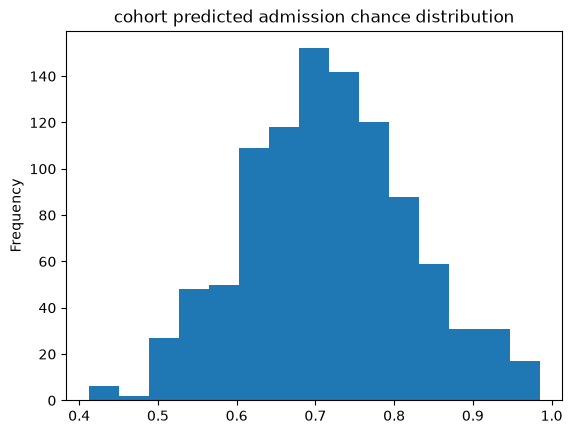

In [9]:
# plot predicted admission chance distribution
report_df['Predicted_Chance'].plot(kind='hist', bins=15, title='cohort predicted admission chance distribution')
plt.show()


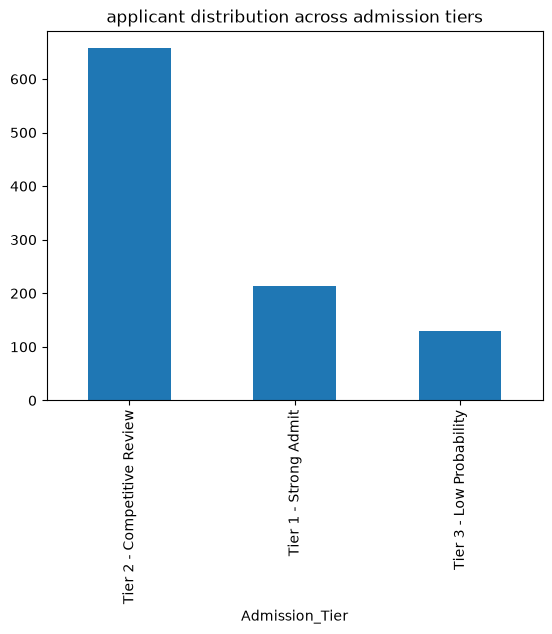

In [10]:
# plot applicant tier composition
report_df['Admission_Tier'].value_counts().plot(kind='bar', title='applicant distribution across admission tiers')
plt.show()


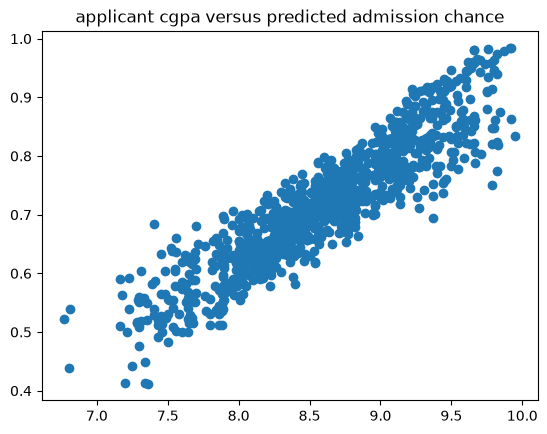

In [11]:
# plot cgpa versus predicted admission chance
plt.scatter(report_df['CGPA'], report_df['Predicted_Chance'])
plt.title('applicant cgpa versus predicted admission chance')
plt.show()


In [12]:
# export detailed batch prediction report
report_df.to_csv('dynamic_prediction_report.csv', index=False)
print('report saved successfully with', len(report_df), 'rows and', report_df.shape[1], 'columns')


report saved successfully with 1000 rows and 15 columns
